# Copilot with SQL and Excel

## Copilot with SQL (SSMS)

### Question 1: Use Github Copilot to create a table SalesData whose columns are CustomerID, Name, Age, City, PurchaseAmount, PurchaseDate and then ask to insert 10,000 rows of random data.

-->  

**Copilot prompt used :**  
*Create a table SalesData with columns CustomerID, Name, Age, City, PurchaseAmount, PurchaseDate and insert 10,000 rows of random data*

```sql
IF OBJECT_ID('dbo.SalesData', 'U') IS NOT NULL
    DROP TABLE dbo.SalesData;
GO

CREATE TABLE dbo.SalesData (
    CustomerID      INT IDENTITY(1,1) PRIMARY KEY,
    Name            VARCHAR(100),
    Age             INT,
    City            VARCHAR(50),
    PurchaseAmount  DECIMAL(10,2),
    PurchaseDate    DATE
);
GO

-- lookup lists for random values
DECLARE @FirstNames TABLE (id INT, fname VARCHAR(30));
INSERT INTO @FirstNames VALUES
(1,'Rahul'),(2,'Priya'),(3,'Amit'),(4,'Neha'),(5,'Rohit'),
(6,'Sneha'),(7,'Vikas'),(8,'Pooja'),(9,'Arjun'),(10,'Kavya'),
(11,'Karan'),(12,'Anjali'),(13,'Sahil'),(14,'Riya'),(15,'Manish');

DECLARE @LastNames TABLE (id INT, lname VARCHAR(30));
INSERT INTO @LastNames VALUES
(1,'Sharma'),(2,'Verma'),(3,'Gupta'),(4,'Singh'),(5,'Kumar'),
(6,'Yadav'),(7,'Mehta'),(8,'Jain'),(9,'Patel'),(10,'Chauhan');

DECLARE @Cities TABLE (id INT, city VARCHAR(50));
INSERT INTO @Cities VALUES
(1,'Delhi'),(2,'Mumbai'),(3,'Bengaluru'),(4,'Chennai'),(5,'Kolkata'),
(6,'Hyderabad'),(7,'Pune'),(8,'Jaipur'),(9,'Ahmedabad'),(10,'Lucknow');

-- generate 10,000 random rows (stored in temp table first so random values stay fixed)
IF OBJECT_ID('tempdb..#RandomRows') IS NOT NULL DROP TABLE #RandomRows;

WITH Numbers AS (
    SELECT TOP (10000) ROW_NUMBER() OVER (ORDER BY (SELECT NULL)) AS rn
    FROM sys.all_objects a
    CROSS JOIN sys.all_objects b
)
SELECT
    rn,
    ABS(CHECKSUM(NEWID())) % 15 + 1                             AS fname_id,
    ABS(CHECKSUM(NEWID())) % 10 + 1                             AS lname_id,
    ABS(CHECKSUM(NEWID())) % 10 + 1                             AS city_id,
    ABS(CHECKSUM(NEWID())) % 48 + 18                            AS Age,             -- 18 to 65
    CAST((ABS(CHECKSUM(NEWID())) % 4990001 + 1000) / 100.0
         AS DECIMAL(10,2))                                      AS PurchaseAmount,  -- 10.00 to 49,910.00
    DATEADD(DAY, -(ABS(CHECKSUM(NEWID())) % 730),
            CAST(GETDATE() AS DATE))                            AS PurchaseDate     -- last 2 years
INTO #RandomRows
FROM Numbers;

INSERT INTO dbo.SalesData (Name, Age, City, PurchaseAmount, PurchaseDate)
SELECT
    f.fname + ' ' + l.lname,
    r.Age,
    c.city,
    r.PurchaseAmount,
    r.PurchaseDate
FROM #RandomRows r
JOIN @FirstNames f ON f.id = r.fname_id
JOIN @LastNames  l ON l.id = r.lname_id
JOIN @Cities     c ON c.id = r.city_id
ORDER BY r.rn;

DROP TABLE #RandomRows;
GO

-- check
SELECT COUNT(*) AS TotalRows FROM dbo.SalesData;
SELECT TOP 10 * FROM dbo.SalesData;
GO


/* ---------------------------------------------------------------------
```

Answer:  
The table **SalesData** was created with six columns. **CustomerID** is an `INT IDENTITY(1,1)` primary key, so SQL Server gives every row a unique ID automatically. **Name** and **City** are `VARCHAR`, **Age** is `INT`, **PurchaseAmount** is `DECIMAL(10,2)` so it can store money with two decimal places, and **PurchaseDate** is `DATE`.

To insert 10,000 rows, Copilot used a **CTE with ROW_NUMBER()** on a cross join of `sys.all_objects`, which quickly gives 10,000 numbers without writing a loop.

For the random values, **ABS(CHECKSUM(NEWID()))** is used. NEWID() gives a new random value for every row, and with the % operator we can keep it in a range. So age comes between 18 and 65, purchase amount between 10 and 49,910, and the date is any day in the last 2 years.

Names and cities are taken from small lookup lists (15 first names, 10 surnames and 10 Indian cities). The random numbers are first saved in a **temp table** and then joined with the lists. This is done because if NEWID() is used directly inside the join, SQL Server can calculate it again and some rows may not match.

Finally, `SELECT COUNT(*)` confirms that **10,000 rows** were inserted, and `SELECT TOP 10` shows a sample of the data.

---
---

### Question 2: Use Copilot to find total sales per city and top 5 cities by revenue.

-->  

**a) Find total sales per city**  

**Copilot prompt used :** *Find total sales per city*

```sql
SELECT
    City,
    COUNT(*)              AS TotalOrders,
    SUM(PurchaseAmount)   AS TotalSales
FROM dbo.SalesData
GROUP BY City
ORDER BY TotalSales DESC;
GO


/* ---------------------------------------------------------------------
```

**b) Top 5 cities by revenue**  

**Copilot prompt used :** *Top 5 cities by revenue*

```sql
SELECT TOP 5
    City,
    SUM(PurchaseAmount) AS TotalRevenue
FROM dbo.SalesData
GROUP BY City
ORDER BY TotalRevenue DESC;
GO


/* ---------------------------------------------------------------------
```

Answer:  
To find total sales per city, the **SUM()** function is used on PurchaseAmount along with **GROUP BY City**. GROUP BY puts all rows of the same city together, and SUM adds up their purchase amounts. I also added **COUNT(\*)** to see how many orders came from each city. The result is sorted with **ORDER BY TotalSales DESC** so the highest city comes first.

For the top 5 cities, the same query is used but with **TOP 5**. Since the data is already sorted from highest to lowest revenue, TOP 5 returns only the five cities with the most revenue.

Because the data is random, each city gets around 1,000 orders and the totals are close to each other. The exact top 5 cities will change every time the insert script is run, since new random values are created each time.

In real business data, this kind of query helps the company see which cities bring the most revenue, so it can focus its marketing and stock in those areas.

---
---

### Question 3: Ask Copilot to find customers with purchases above average.

-->  

**Copilot prompt used :** *Find customers with purchases above average*

```sql
-- average purchase amount for reference
SELECT AVG(PurchaseAmount) AS AveragePurchase FROM dbo.SalesData;

-- customers whose purchase is above the average
SELECT
    CustomerID,
    Name,
    Age,
    City,
    PurchaseAmount,
    PurchaseDate
FROM dbo.SalesData
WHERE PurchaseAmount > (SELECT AVG(PurchaseAmount) FROM dbo.SalesData)
ORDER BY PurchaseAmount DESC;

-- count of such customers
SELECT COUNT(*) AS CustomersAboveAverage
FROM dbo.SalesData
WHERE PurchaseAmount > (SELECT AVG(PurchaseAmount) FROM dbo.SalesData);
GO
```

Answer:  
To find these customers, a **subquery** is used. The inner query `SELECT AVG(PurchaseAmount) FROM SalesData` first calculates the average purchase amount of the whole table. The outer query then returns only those rows where **PurchaseAmount is greater than that average**.

The first query just shows the average value for reference. The second one lists all the customers above average, sorted from the highest purchase. The last one counts how many such customers there are.

Since the purchase amount is generated randomly and evenly between 10 and about 49,910, the average comes close to **25,000**, and roughly **half of the customers (around 5,000)** are above the average.

The good thing about using a subquery is that the average is calculated automatically every time, so if new data is added we do not need to change the query.

For a business, these above-average customers are the **high value customers**, and the company can target them with special offers or loyalty programs.

---
---

## Copilot in Excel

Dataset : **Excel_dataset.csv** (550 rows, 6 columns)

The Copilot steps were done in Excel. The same steps are also done below in Python (pandas) so the results can be checked and shown in this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Excel_dataset.csv')
print("Shape :", df.shape)
df.head(10)

Shape : (550, 6)


,Customer_Name,Region,Product,Sales,Quantity,Order_Date
0,Karan,NaN,Monitor,NaN,4,2023-06-08
1,Riya,South,Monitor,NaN,2,2023-03-18
2,Amit,West,NaN,300.0,two,2023-07-01
3,Sneha,NaN,Tablet,300.0,4,2023-04-01
4,Sneha,West,Phone,NaN,4,2023-05-15
5,Sneha,South,Laptop,300.0,NaN,2023-05-01
6,Rahul,South,NaN,400.0,4,2023-05-11
7,Sneha,South,Phone,400.0,NaN,2023-06-04
8,Riya,North,Monitor,400.0,1,2023-08-27
9,Priya,West,Laptop,400.0,4,2023-10-09


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer_Name  482 non-null    str    
 1   Region         358 non-null    str    
 2   Product        445 non-null    str    
 3   Sales          383 non-null    float64
 4   Quantity       460 non-null    str    
 5   Order_Date     550 non-null    str    
dtypes: float64(1), str(5)
memory usage: 25.9 KB


### Question 4: Identify and handle missing values in the dataset using Copilot.

-->  

**Copilot prompt used :**  
*Find the missing values in each column of this table and suggest how to handle them*

In [3]:
# missing values per column
missing = pd.DataFrame({'Missing Count': df.isnull().sum(),
                        'Missing %': (df.isnull().sum() / len(df) * 100).round(2)})
missing

,Missing Count,Missing %
Customer_Name,68,12.36
Region,192,34.91
Product,105,19.09
Sales,167,30.36
Quantity,90,16.36
Order_Date,0,0.00


In [4]:
# Quantity has text 'two' instead of number
print(df['Quantity'].value_counts(dropna=False))

Quantity
4      103
two     98
NaN     90
2       89
3       88
1       82
Name: count, dtype: int64


**Copilot prompt used :**  
*Replace the text 'two' with 2 in Quantity, fill blank Sales and Quantity with the median, and fill blank Customer_Name, Region and Product with 'Unknown'*

In [5]:
# fix wrong text value
df['Quantity'] = df['Quantity'].replace('two', '2')
df['Quantity'] = pd.to_numeric(df['Quantity'])

# numeric columns -> median
print("Sales median :", df['Sales'].median())
print("Quantity median :", df['Quantity'].median())
df['Sales'] = df['Sales'].fillna(df['Sales'].median())
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())

# text columns -> 'Unknown'
for col in ['Customer_Name', 'Region', 'Product']:
    df[col] = df[col].fillna('Unknown')

df['Order_Date'] = pd.to_datetime(df['Order_Date'])

print()
print(df.isnull().sum())

Sales median : 300.0
Quantity median : 2.0

Customer_Name    0
Region           0
Product          0
Sales            0
Quantity         0
Order_Date       0
dtype: int64


Answer:  
First I asked Copilot to find the missing values in each column. It showed that **5 out of 6 columns had missing data**. **Region** had the most with **192 blanks (34.9%)**, then **Sales with 167 (30.4%)**, **Product with 105 (19.1%)**, **Quantity with 90 (16.4%)** and **Customer_Name with 68 (12.4%)**. Only **Order_Date** was complete.

In the Sales column, the missing values were of two types. Some cells were just blank and some had the text **"NA"** written in them. Both mean the same thing, so both were treated as missing.

Another problem was in the **Quantity** column, where **98 rows had the word "two"** instead of the number 2. Because of this Excel was treating the whole column as text. Copilot suggested using **Find & Replace** to change "two" to 2, after which the column became numeric.

For handling the missing values, Copilot suggested different methods for different columns. For the numeric columns **Sales and Quantity**, blanks were filled with the **median** (300 for Sales and 2 for Quantity). Median is better than mean here because it does not get affected by extreme values. For the text columns **Customer_Name, Region and Product**, blanks were filled with **"Unknown"**. I did not delete these rows because Region alone is missing in about 35% of the data, and deleting would remove too much information.

After this step, the dataset has **0 missing values** in all columns.

---
---

### Question 5: Identify duplicate rows and remove duplicates using Copilot suggestion.

-->  

**Copilot prompt used :**  
*Highlight the duplicate rows in this table*

In [6]:
print("Duplicate rows :", df.duplicated().sum())

# showing some duplicate rows with their original copy
df[df.duplicated(keep=False)].sort_values(['Customer_Name', 'Order_Date']).head(10)

Duplicate rows : 51


,Customer_Name,Region,Product,Sales,Quantity,Order_Date
311,Amit,Unknown,Phone,300.0,4.0,2023-04-26
522,Amit,Unknown,Phone,300.0,4.0,2023-04-26
304,Amit,East,Monitor,200.0,2.0,2023-06-19
500,Amit,East,Monitor,200.0,2.0,2023-06-19
173,Amit,North,Monitor,400.0,2.0,2023-07-06
528,Amit,North,Monitor,400.0,2.0,2023-07-06
467,Amit,West,Tablet,300.0,2.0,2023-07-07
542,Amit,West,Tablet,300.0,2.0,2023-07-07
233,Amit,East,Phone,300.0,4.0,2023-09-02
532,Amit,East,Phone,300.0,4.0,2023-09-02


**Copilot prompt used :**  
*Remove the duplicate rows from this table*

In [7]:
print("Rows before :", len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after  :", len(df))
print("Duplicates now :", df.duplicated().sum())

Rows before : 550
Rows after  : 499
Duplicates now : 0


Answer:  
To find duplicates I asked Copilot to highlight the duplicate rows. A row is counted as duplicate when **all six columns** (name, region, product, sales, quantity and date) are exactly the same as another row. Copilot used **Conditional Formatting** to highlight them.

It found **51 duplicate rows** in the dataset. When I checked, most of them were in the **last part of the sheet** (from around row 500 onwards). It looks like some rows were copied and pasted again by mistake at the end of the data.

To remove them, Copilot suggested using **Data > Remove Duplicates** with all columns selected. This keeps the first copy of each row and deletes the extra ones.

After removing, the dataset went from **550 rows to 499 rows**, and now there are **0 duplicates**.

Removing duplicates is important because if the same order is counted twice, the total sales and all the other analysis would come out higher than the real value.

---
---

### Question 6: Generate column chart OR bar chart and interpret which region has highest sales.

-->  

**Copilot prompt used :**  
*Create a column chart showing total sales by region*

Region
Unknown    49300.0
West       22400.0
South      21500.0
East       20500.0
North      20200.0
Name: Sales, dtype: float64


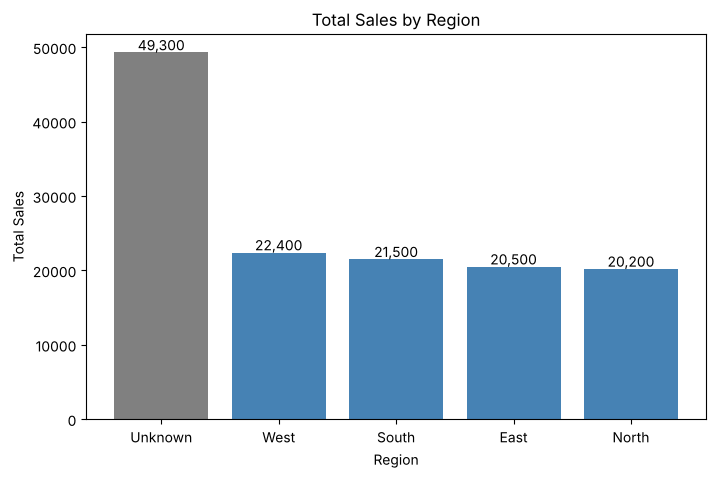

In [8]:
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
print(region_sales)

plt.figure(figsize=(8,5))
bars = plt.bar(region_sales.index, region_sales.values, color=['grey' if r == 'Unknown' else 'steelblue' for r in region_sales.index])
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 300, f'{int(b.get_height()):,}', ha='center')
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

Answer:  
A **column chart** of total sales by region was created using Copilot. Excel first sums up the Sales column for each region and then shows each region as a bar.

The **"Unknown"** bar is the tallest with **49,300**, but this is not a real region. It is made up of all the rows where the region was missing, which is about 35% of the data, so I have kept it in grey and not counted it as a region.

Among the actual regions, **West has the highest sales with 22,400**. After that comes **South with 21,500**, **East with 20,500** and **North with 20,200** as the lowest.

The difference between the four regions is not very big, only around **2,200** between the highest and lowest. So sales are spread quite evenly across all regions, with West slightly ahead.

One thing to note is that because so many rows have an unknown region, the real ranking could change if that data is collected properly.

---
---

### Question 7: Create a pivot table showing total sales by region and product.

-->  

**Copilot prompt used :**  
*Create a pivot table with Region in rows, Product in columns and sum of Sales as values*

In [9]:
pivot = pd.pivot_table(df, index='Region', columns='Product', values='Sales',
                       aggfunc='sum', margins=True, margins_name='Grand Total')
pivot

Product,Laptop,Monitor,Phone,Tablet,Unknown,Grand Total
Region,,,,,,
East,3300.0,5600.0,3900.0,3600.0,4100.0,20500.0
North,3200.0,4700.0,3400.0,4000.0,4900.0,20200.0
South,5300.0,4900.0,4000.0,3800.0,3500.0,21500.0
Unknown,9900.0,10400.0,9100.0,9400.0,10500.0,49300.0
West,4700.0,4800.0,6800.0,3300.0,2800.0,22400.0
Grand Total,26400.0,30400.0,27200.0,24100.0,25800.0,133900.0


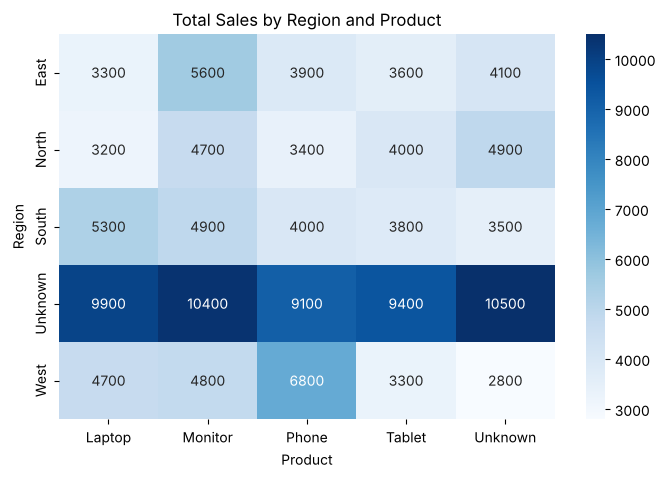

In [10]:
plt.figure(figsize=(8,5))
sns.heatmap(pivot.drop(index='Grand Total', columns='Grand Total'), annot=True, fmt='.0f', cmap='Blues')
plt.title('Total Sales by Region and Product')
plt.show()

Answer:  
Copilot created a **pivot table** with **Region in rows**, **Product in columns** and **Sum of Sales** as the values. Excel also adds a **Grand Total** row and column automatically.

Looking at the products, **Monitor has the highest total sales (30,400)**, followed by **Phone (27,200)**, **Laptop (26,400)** and **Tablet (24,100)**, which is the lowest.

For each region, the top product is different. In **East and North, Monitor** sells the most (5,600 and 4,700). In **South, Laptop** is the top product with 5,300. And in **West, Phone** is the clear leader with **6,800**, which is the **highest single value** in the whole table among the known regions and products.

The lowest combination is **West - Tablet** with only 3,300.

So the pivot table helps to see which product is doing well in which region. For example, the company can push more phones in the West and more laptops in the South.

---
---

### Question 8: Use Copilot to generate a new calculated column Total Sales.

-->  

**Copilot prompt used :**  
*Add a new column Total_Sales which is Sales multiplied by Quantity*

Excel formula generated by Copilot (in cell G2, then filled down) :  
```
=D2*E2
```

In [11]:
df['Total_Sales'] = df['Sales'] * df['Quantity']
df.head(10)

,Customer_Name,Region,Product,Sales,Quantity,Order_Date,Total_Sales
0,Karan,Unknown,Monitor,300.0,4.0,2023-06-08,1200.0
1,Riya,South,Monitor,300.0,2.0,2023-03-18,600.0
2,Amit,West,Unknown,300.0,2.0,2023-07-01,600.0
3,Sneha,Unknown,Tablet,300.0,4.0,2023-04-01,1200.0
4,Sneha,West,Phone,300.0,4.0,2023-05-15,1200.0
5,Sneha,South,Laptop,300.0,2.0,2023-05-01,600.0
6,Rahul,South,Unknown,400.0,4.0,2023-05-11,1600.0
7,Sneha,South,Phone,400.0,2.0,2023-06-04,800.0
8,Riya,North,Monitor,400.0,1.0,2023-08-27,400.0
9,Priya,West,Laptop,400.0,4.0,2023-10-09,1600.0


In [12]:
print("Sum of Sales column       :", df['Sales'].sum())
print("Sum of Total_Sales column :", df['Total_Sales'].sum())
df['Total_Sales'].describe()

Sum of Sales column       : 133900.0
Sum of Total_Sales column : 316800.0


count     499.000000
mean      634.869739
std       352.139948
min       100.000000
25%       400.000000
50%       600.000000
75%       800.000000
max      1600.000000
Name: Total_Sales, dtype: float64

Answer:  
A new calculated column **Total_Sales** was added using Copilot. Here the **Sales** column works like the price of one unit, so the total value of each order is **Sales x Quantity**. Copilot gave the formula **=D2\*E2**, which was then filled down for all rows.

For example, the first row has Sales of 300 and Quantity of 4, so its Total_Sales becomes **1,200**.

After adding this column, the **overall total sales became 3,16,800**, while the sum of just the Sales column was 1,33,900. This shows that only looking at the Sales column would give a much lower picture of the actual revenue.

The Total_Sales of a single order ranges from **100 to 1,600**, and the **average order value is about 635**.

This column is more useful for analysis because it shows the real value of each order, considering both price and quantity.

---
---

### Question 9: Summarize the dataset and find the key insights.

-->  

**Copilot prompt used :**  
*Summarize this data and give me the key insights*

In [13]:
print("Total orders      :", len(df))
print("Total revenue     :", df['Total_Sales'].sum())
print("Total quantity    :", df['Quantity'].sum())
print("Average order     :", round(df['Total_Sales'].mean(), 2))
print("Date range        :", df['Order_Date'].min().date(), "to", df['Order_Date'].max().date())

Total orders      : 499
Total revenue     : 316800.0
Total quantity    : 1187.0
Average order     : 634.87
Date range        : 2023-01-01 to 2023-12-31


In [14]:
print("Revenue by Product")
print(df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False))
print()
print("Revenue by Region")
print(df.groupby('Region')['Total_Sales'].sum().sort_values(ascending=False))
print()
print("Revenue by Customer")
print(df.groupby('Customer_Name')['Total_Sales'].sum().sort_values(ascending=False))

Revenue by Product
Product
Monitor    72200.0
Phone      63900.0
Laptop     61300.0
Unknown    61200.0
Tablet     58200.0
Name: Total_Sales, dtype: float64

Revenue by Region
Region
Unknown    118800.0
West        56900.0
South       51000.0
East        47800.0
North       42300.0
Name: Total_Sales, dtype: float64

Revenue by Customer
Customer_Name
Sneha      54000.0
Amit       51900.0
Karan      44600.0
Unknown    42100.0
Riya       42100.0
Priya      41200.0
Rahul      40900.0
Name: Total_Sales, dtype: float64


Jan    22000.0
Feb    21700.0
Mar    27700.0
Apr    29100.0
May    29400.0
Jun    26400.0
Jul    27600.0
Aug    21500.0
Sep    24500.0
Oct    33100.0
Nov    19600.0
Dec    34200.0
Name: Total_Sales, dtype: float64


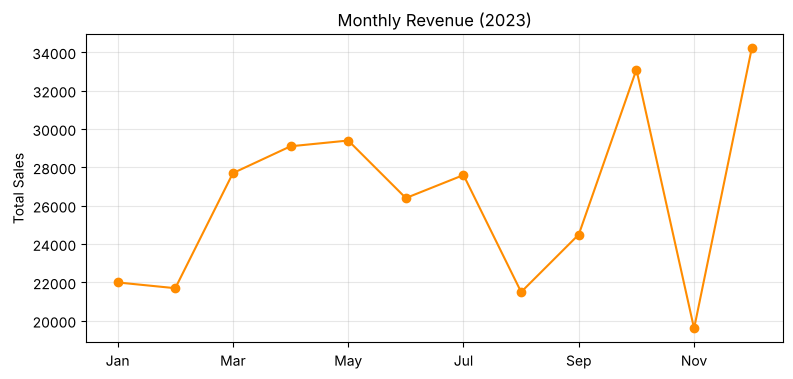

In [15]:
monthly = df.groupby(df['Order_Date'].dt.month)['Total_Sales'].sum()
monthly.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print(monthly)

monthly.plot(kind='line', marker='o', figsize=(9,4), color='darkorange')
plt.title('Monthly Revenue (2023)')
plt.ylabel('Total Sales')
plt.grid(alpha=0.3)
plt.show()

Answer:  
After cleaning, the dataset has **499 orders** from **1 January 2023 to 31 December 2023**. The **total revenue is 3,16,800**, total quantity sold is **1,187 units** and the **average order value is about 635**. There are 6 customers and 4 products (Laptop, Monitor, Phone and Tablet).

The key insights are:

**Monitor is the best selling product**, with revenue of **72,200**. After that are Phone (63,900) and Laptop (61,300). **Tablet is the weakest** at 58,200.

Among the known regions, **West brings the most revenue (56,900)**, and **North is the lowest (42,300)**. But the biggest share, **1,18,800**, comes from rows where region is **Unknown**, which shows a big data quality problem.

**Sneha (54,000) and Amit (51,900)** are the top customers by revenue, while **Rahul** is the lowest at 40,900.

Month wise, **December (34,200) and October (33,100)** were the best months, which could be due to the festive season. **November (19,600)** was the weakest month, followed by August.

Finally, the data quality was poor. Around **35% of regions, 30% of sales values and 19% of products were missing**, and there were **51 duplicate rows**. The company should improve how data is entered so that the analysis can be more accurate.

---
---

### Question 10: Generate VBA code using Copilot for cleaning data (removing duplicates, filling null values, format table).

-->  

**Copilot prompt used :**  
*Write a VBA macro to clean this sheet: remove duplicate rows, replace 'two' with 2 in Quantity, fill blank Sales and Quantity with the median, fill blank text cells with 'Unknown', and format the data as a table*

```vba
Sub CleanData()

    Dim ws As Worksheet
    Dim lastRow As Long, lastCol As Long
    Dim rng As Range, cell As Range
    Dim col As Long
    Dim medSales As Double, medQty As Double
    Dim tbl As ListObject

    Set ws = ThisWorkbook.Sheets(1)
    Application.ScreenUpdating = False

    ' remove table format if already applied
    If ws.ListObjects.Count > 0 Then ws.ListObjects(1).Unlist

    lastRow = ws.Cells(ws.Rows.Count, "F").End(xlUp).Row
    lastCol = ws.Cells(1, ws.Columns.Count).End(xlToLeft).Column

    ' 1. fix wrong values
    ws.Range("E2:E" & lastRow).Replace What:="two", Replacement:="2", LookAt:=xlWhole
    ws.Range("D2:D" & lastRow).Replace What:="NA", Replacement:="", LookAt:=xlWhole

    ' convert text numbers to real numbers
    For Each cell In ws.Range("D2:E" & lastRow)
        If cell.Value <> "" Then cell.Value = CDbl(cell.Value)
    Next cell

    ' 2. remove duplicates (all columns)
    ws.Range(ws.Cells(1, 1), ws.Cells(lastRow, lastCol)).RemoveDuplicates _
        Columns:=Array(1, 2, 3, 4, 5, 6), Header:=xlYes

    lastRow = ws.Cells(ws.Rows.Count, "F").End(xlUp).Row

    ' 3. fill null values
    medSales = Application.WorksheetFunction.Median(ws.Range("D2:D" & lastRow))
    medQty = Application.WorksheetFunction.Median(ws.Range("E2:E" & lastRow))

    For Each cell In ws.Range("D2:D" & lastRow)
        If IsEmpty(cell) Then cell.Value = medSales
    Next cell

    For Each cell In ws.Range("E2:E" & lastRow)
        If IsEmpty(cell) Then cell.Value = medQty
    Next cell

    For col = 1 To 3   ' Customer_Name, Region, Product
        For Each cell In ws.Range(ws.Cells(2, col), ws.Cells(lastRow, col))
            If Trim(cell.Value) = "" Then cell.Value = "Unknown"
        Next cell
    Next col

    ' 4. format as table
    Set rng = ws.Range(ws.Cells(1, 1), ws.Cells(lastRow, lastCol))
    Set tbl = ws.ListObjects.Add(xlSrcRange, rng, , xlYes)
    tbl.Name = "CleanSalesData"
    tbl.TableStyle = "TableStyleMedium2"

    ws.Range("D2:D" & lastRow).NumberFormat = "#,##0"
    ws.Range("E2:E" & lastRow).NumberFormat = "0"
    ws.Range("F2:F" & lastRow).NumberFormat = "dd-mmm-yyyy"
    ws.Rows(1).Font.Bold = True
    ws.Columns.AutoFit

    Application.ScreenUpdating = True
    MsgBox "Data cleaned! Rows left: " & (lastRow - 1), vbInformation

End Sub
```

Answer:  
Copilot was asked to write a **VBA macro** that does all the cleaning steps in one click. To use it, press **Alt + F11**, go to **Insert > Module**, paste the code and run **CleanData**. The file has to be saved as **.xlsm** to keep the macro.

The macro works in four parts. First it **fixes wrong values**. It replaces the text "two" with 2 in the Quantity column and clears the "NA" text from Sales, so that both columns become proper numbers.

Next, it **removes duplicates** using the `RemoveDuplicates` method with all six columns selected. This deletes the 51 repeated rows and keeps only the first copy.

After that, it **fills the null values**. It uses `WorksheetFunction.Median` to find the median of Sales and Quantity and fills the blank cells with it. For the text columns Customer_Name, Region and Product, it fills the blanks with "Unknown". This is the same logic that was used in Question 4.

Finally, it **formats the data as a table** using `ListObjects.Add`, applies a table style, sets number and date formats, makes the header bold and auto-fits the column width. At the end a message box shows how many rows are left.

The benefit of using VBA is that if a new file with the same problems comes next month, the whole cleaning can be done by just running the macro again instead of repeating every step by hand.